Connected to Python 3.13.0

In [ ]:
import os
import sys
import numpy as np
import anndata as ad
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Add current directory to path for imports
current_dir = os.path.dirname(os.path.abspath(__file__))
if current_dir not in sys.path:
    sys.path.insert(0, current_dir)

from visualization_functions import (
    plot_cell_counts_comparison,
    plot_stacked_bar_by_odt,
    plot_scatter_and_density_by_medium,
    plot_violin_comparison_m9_m9f,
)

In [ ]:
# Constants for better maintainability
UMI_THRESHOLD = 100
DATA_PATH = "data/Anndata/with_metadata/"
OUTPUT_PATH = "data/Anndata/filtered"
INPUT_FILE = "GeneFull_raw_unique_mult_with_metadata.h5ad"
OUTPUT_FILE = "GeneFull_raw_unique_mult_with_metadata_grouped_filtered_100UMI.h5ad"

In [ ]:
def create_group_from_od(od_value: str) -> str:
    """
    Create Group variable from OD value.
    Extracts the medium and OD parts, removing the middle letter (A, B, C).

    Example: "OD M9_C_OD3" -> "M9_OD3"
    Example: "M9_C_OD3" -> "M9_OD3"

    Args:
        od_value (str): Original OD value

    Returns:
        str: Processed group name
    """
    if not isinstance(od_value, str):
        return str(od_value)

    # Remove "OD " prefix if present
    processed_value = od_value[3:] if od_value.startswith("OD ") else od_value

    # Split by underscore to get parts
    parts = processed_value.split("_")

    if len(parts) >= 3:
        # Get the medium part (first part) and OD part (last part)
        medium_part = parts[0]  # e.g., "M9"
        od_part = parts[-1]  # e.g., "OD3"
        return f"{medium_part}_{od_part}"

    return od_value

In [ ]:
def add_suffix_columns(adata: ad.AnnData) -> None:
    """
    Add suffix columns for RepTech and RepBio in-place.

    Args:
        adata (ad.AnnData): AnnData object to modify
    """
    # Extract suffixes efficiently using vectorized operations
    adata.obs["RepTech_suffix"] = adata.obs["RepTech"].str.split("_").str[-1]
    adata.obs["RepBio_suffix"] = adata.obs["RepBio"].str.split("_").str[-1]

In [ ]:
def calculate_qc_metrics(adata: ad.AnnData) -> None:
    """
    Calculate QC metrics (n_counts, n_genes) in-place.

    Args:
        adata (ad.AnnData): AnnData object to modify
    """
    # Calculate QC metrics efficiently
    adata.obs["n_counts"] = np.array(adata.X.sum(axis=1)).flatten()
    adata.obs["n_genes"] = np.array((adata.X > 0).sum(axis=1)).flatten()

In [ ]:
def print_group_summary(adata: ad.AnnData) -> None:
    """
    Print summary of Group variable creation.

    Args:
        adata (ad.AnnData): AnnData object to analyze
    """
    print(f"📋 OD to Group mapping:")
    unique_mappings = adata.obs[["OD", "Group"]].drop_duplicates()
    for _, row in unique_mappings.iterrows():
        print(f"   {row['OD']} -> {row['Group']}")

    print(f"\n🧬 New Group column created!")
    print(f"🔢 Number of unique Group values: {len(adata.obs['Group'].unique())}")
    print(f"📋 Unique Group values: {sorted(adata.obs['Group'].unique())}")

    # Show distribution of cells per Group
    print(f"\n📊 Distribution of cells per Group:")
    group_counts = adata.obs["Group"].value_counts()
    for group, count in group_counts.items():
        print(f"   {group}: {count:,} cells")

In [ ]:
def filter_cells_by_umi(
    adata: ad.AnnData, threshold: int = UMI_THRESHOLD
) -> ad.AnnData:
    """
    Filter cells based on UMI count threshold.

    Args:
        adata (ad.AnnData): Input AnnData object
        threshold (int): Minimum UMI count threshold

    Returns:
        ad.AnnData: Filtered AnnData object
    """
    initial_cells = adata.n_obs
    print(f"📊 Before filtering: {initial_cells:,} cells")

    # Create mask for cells to keep
    cells_to_keep = adata.obs["n_counts"] >= threshold

    # Apply filtering
    adata_filtered = adata[cells_to_keep, :].copy()

    final_cells = adata_filtered.n_obs
    removed_cells = initial_cells - final_cells
    retention_rate = (final_cells / initial_cells) * 100

    print(f"📊 After filtering (n_counts >= {threshold}): {final_cells:,} cells")
    print(f"🗑️ Removed {removed_cells:,} cells")
    print(f"✅ Retention rate: {retention_rate:.1f}%")

    return adata_filtered

In [ ]:
def print_filtering_summary(adata: ad.AnnData) -> None:
    """
    Print summary statistics after filtering.

    Args:
        adata (ad.AnnData): Filtered AnnData object
    """
    n_counts_stats = adata.obs["n_counts"]
    print(f"\n📈 Summary statistics after filtering:")
    print(f"   Mean n_counts: {n_counts_stats.mean():.2f}")
    print(f"   Median n_counts: {n_counts_stats.median():.2f}")
    print(f"   Min n_counts: {n_counts_stats.min():.2f}")
    print(f"   Max n_counts: {n_counts_stats.max():.2f}")

In [ ]:
def run_visualizations(adata: ad.AnnData) -> None:
    """
    Run all visualization functions.

    Args:
        adata (ad.AnnData): AnnData object for visualization
    """
    print("🔧 Running all visualization functions...")

    # 1. Stacked bar plot by ODt
    print("\n1️⃣ Creating stacked bar plot by ODt...")
    total_all, total_by_medium = plot_stacked_bar_by_odt(adata)

    # 2. Scatter plots and density distributions
    print("\n2️⃣ Creating scatter plots and density distributions...")
    plot_scatter_and_density_by_medium(adata)

    # 3. Violin plot comparison M9 vs M9F
    print("\n3️⃣ Creating violin plot comparison...")
    plot_violin_comparison_m9_m9f(adata)

    print("\n✅ All visualization functions completed successfully!")

In [ ]:
# Set working directory
os.chdir(os.path.dirname(os.path.dirname(os.path.dirname(os.path.abspath(__file__)))))

In [ ]:
# Load data
print("📂 Loading data...")
adata_original = ad.read_h5ad(os.path.join(DATA_PATH, INPUT_FILE))
adata = adata_original.copy()

📂 Loading data...


In [ ]:
# Process Group variable
print("🔧 Creating new Group variable from OD column...")
adata.obs["Group"] = adata.obs["OD"].apply(create_group_from_od)
print_group_summary(adata)

🔧 Creating new Group variable from OD column...
📋 OD to Group mapping:
   M9_B_OD1 -> M9_OD1
   M9F_B_OD1 -> M9F_OD1
   M9F_B_OD2 -> M9F_OD2
   M9_A_OD2 -> M9_OD2
   M9F_B_OD3 -> M9F_OD3
   M9_C_OD3 -> M9_OD3
   M9F_C_OD3 -> M9F_OD3
   M9F_C_OD1 -> M9F_OD1
   M9_A_OD1 -> M9_OD1
   M9F_C_OD2 -> M9F_OD2
   M9_C_OD1 -> M9_OD1
   M9F_A_OD2 -> M9F_OD2
   M9_B_OD3 -> M9_OD3
   M9_C_OD2 -> M9_OD2
   M9_B_OD2 -> M9_OD2
   M9F_A_OD3 -> M9F_OD3
   M9F_A_OD1 -> M9F_OD1
   M9_A_OD3 -> M9_OD3

🧬 New Group column created!
🔢 Number of unique Group values: 6
📋 Unique Group values: ['M9F_OD1', 'M9F_OD2', 'M9F_OD3', 'M9_OD1', 'M9_OD2', 'M9_OD3']

📊 Distribution of cells per Group:
   M9_OD1: 136,800 cells
   M9F_OD1: 136,800 cells
   M9F_OD2: 136,800 cells
   M9_OD2: 136,800 cells
   M9F_OD3: 136,800 cells
   M9_OD3: 136,800 cells


In [ ]:
# Calculate QC metrics
print("\n🧮 Calculating QC metrics...")
calculate_qc_metrics(adata)


🧮 Calculating QC metrics...


In [ ]:
# Add suffix columns
print("🏷️ Adding suffix columns...")
add_suffix_columns(adata)

🏷️ Adding suffix columns...


In [ ]:
# Show basic info about the data
print("\n📊 Basic data exploration:")
print(f"🔢 adata.obs columns: {list(adata.obs.columns)}")
print(f"🔢 adata.var columns: {list(adata.var.columns)}")


📊 Basic data exploration:
🔢 adata.obs columns: ['barcode', 'Well_loc_rd1', 'Well_loc_rd2', 'Well_loc_rd3', 'CultureMedium', 'RepBio', 'OD', 'RepTech', 'ODt', 'OD_theoric', 'OD_measured', 'Extracted_Sequence_rd1', 'Group', 'n_counts', 'n_genes', 'RepTech_suffix', 'RepBio_suffix']
🔢 adata.var columns: ['gene_id', 'final_gene_name', 'symbol_renamed', 'Gene Type', 'Name', 'Protein accession', 'symbol_old', 'locus_tag_old']


In [ ]:
# Show QC metrics statistics
print("\n📈 QC metrics statistics:")
print("n_counts statistics:")
print(adata.obs["n_counts"].describe())
print("\nn_genes statistics:")
print(adata.obs["n_genes"].describe())


📈 QC metrics statistics:
n_counts statistics:
count    820800.000000
mean         62.851795
std         137.906700
min           0.000000
25%           6.000000
50%          19.000000
75%          56.000000
max        9449.000000
Name: n_counts, dtype: float64

n_genes statistics:
count    820800.000000
mean         38.745412
std          65.655428
min           0.000000
25%           6.000000
50%          16.000000
75%          40.000000
max        1956.000000
Name: n_genes, dtype: float64


In [ ]:
# Show group statistics
print("\n📋 Group statistics by RepTech:")
print(adata.obs.groupby("RepTech")["n_counts"].describe())
print(f"\nCount by RepTech:")
print(adata.obs.groupby("RepTech")["n_counts"].count())


📋 Group statistics by RepTech:
              count        mean         std  min   25%   50%     75%     max
RepTech                                                                     
M9F_A_OD1_1  9120.0  210.298465  272.378435  3.0  52.0  80.0  284.25  3566.0
M9F_A_OD1_2  9120.0   83.689912  119.415423  0.0  16.0  27.0  115.00  1413.0
M9F_A_OD1_3  9120.0   92.531908  138.968423  0.0  17.0  28.0  124.00  1708.0
M9F_A_OD1_4  9120.0  151.516776  228.248865  0.0  30.0  44.0  200.00  2536.0
M9F_A_OD1_5  9120.0  143.762939  221.024049  0.0  25.0  38.0  198.00  3021.0
...             ...         ...         ...  ...   ...   ...     ...     ...
M9_C_OD3_1   9120.0    7.128399   26.228016  0.0   0.0   0.0    3.00   589.0
M9_C_OD3_2   9120.0   11.354167   35.577140  0.0   0.0   1.0    6.00   720.0
M9_C_OD3_3   9120.0    3.690461    4.571053  0.0   0.0   2.0    5.25    55.0
M9_C_OD3_4   9120.0   10.077412   27.783075  0.0   0.0   2.0    7.00   607.0
M9_C_OD3_5   9120.0    7.510965   24.583975 

<ipython-input-17-269dc4242fe8>:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(adata.obs.groupby("RepTech")["n_counts"].describe())
<ipython-input-17-269dc4242fe8>:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(adata.obs.groupby("RepTech")["n_counts"].count())


In [ ]:
# Filter cells by UMI threshold
print(f"\n🔍 Filtering cells with n_counts < {UMI_THRESHOLD}...")
adata_filtered = filter_cells_by_umi(adata, UMI_THRESHOLD)
print_filtering_summary(adata_filtered)

# Print prominent summary
print("\n" + "=" * 60)
print("📊 UMI FILTERING SUMMARY")
print("=" * 60)
print(f"🔢 Initial cells:          {adata.n_obs:,}")
print(f"🔢 Cells after filtering:  {adata_filtered.n_obs:,}")
print(f"🗑️ Cells removed:          {adata.n_obs - adata_filtered.n_obs:,}")
print(f"✅ Retention rate:         {(adata_filtered.n_obs / adata.n_obs) * 100:.1f}%")
print(f"🎯 Threshold applied:      n_counts >= {UMI_THRESHOLD}")
print("=" * 60)


🔍 Filtering cells with n_counts < 100...
📊 Before filtering: 820,800 cells
📊 After filtering (n_counts >= 100): 132,233 cells
🗑️ Removed 688,567 cells
✅ Retention rate: 16.1%

📈 Summary statistics after filtering:
   Mean n_counts: 276.52
   Median n_counts: 197.00
   Min n_counts: 100.00
   Max n_counts: 9449.00

📊 UMI FILTERING SUMMARY
🔢 Initial cells:          820,800
🔢 Cells after filtering:  132,233
🗑️ Cells removed:          688,567
✅ Retention rate:         16.1%
🎯 Threshold applied:      n_counts >= 100



📊 Creating comparison plot...


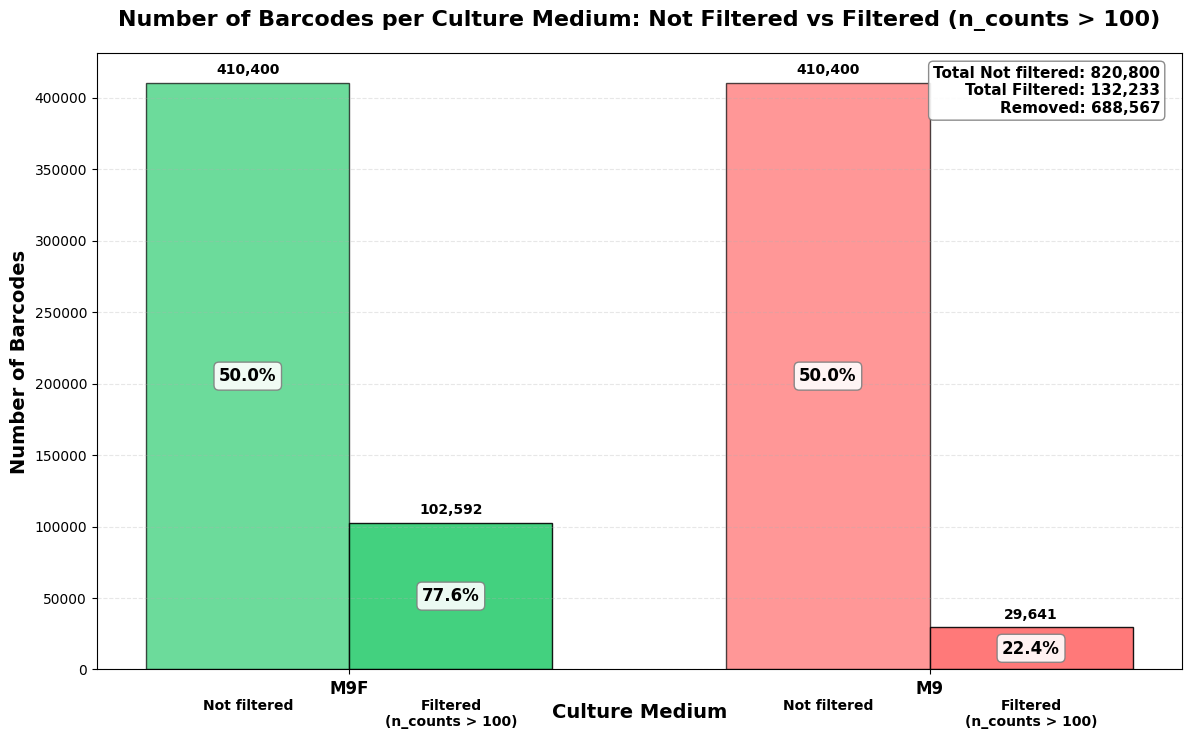


📊 Cell Count Summary: Before vs After Filtering (n_counts ≥ 100):
📈 Total barcodes before filtering: 820,800
📈 Total barcodes after filtering: 132,233
🗑️ Barcodes removed: 688,567 (83.9%)

🍽️ Breakdown by Culture Medium:

   M9F:
     Before: 410,400 barcodes
     After: 102,592 barcodes
     Removed: 307,808 barcodes (75.0%)

   M9:
     Before: 410,400 barcodes
     After: 29,641 barcodes
     Removed: 380,759 barcodes (92.8%)


In [ ]:
# Create comparison plot
print("\n📊 Creating comparison plot...")
plot_cell_counts_comparison(
    adata_original, adata_filtered, filter_threshold=UMI_THRESHOLD
)

🔧 Running all visualization functions...

1️⃣ Creating stacked bar plot by ODt...


/Users/valentingoupille/Internship_Val_Goupille_2025/code/Local_analysis/visualization_functions.py:270: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby(["group", "RepBio", "RepTech_suffix"])
/Users/valentingoupille/Internship_Val_Goupille_2025/code/Local_analysis/visualization_functions.py:405: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby("CultureMedium")


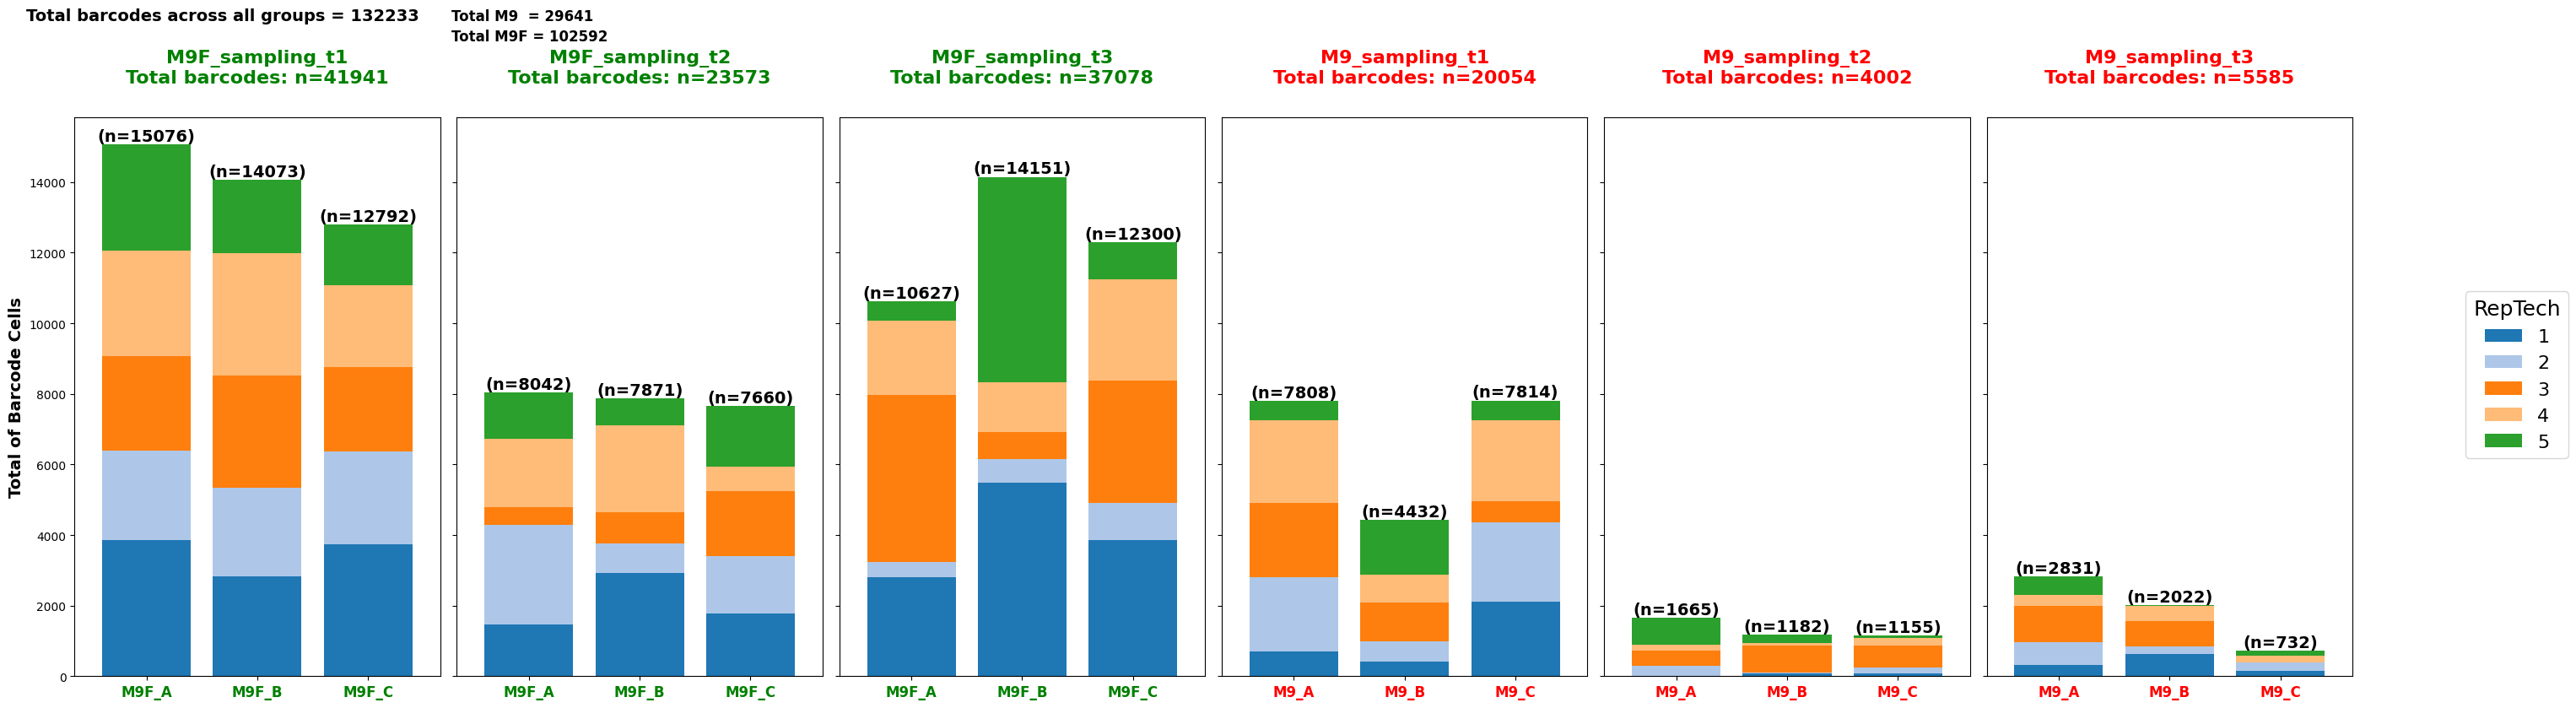


2️⃣ Creating scatter plots and density distributions...

🍽️ Statistics by Culture Medium:

   M9:
     Cells: 29,641
     Mean n_counts: 248
     Mean n_genes: 146

   M9F:
     Cells: 102,592
     Mean n_counts: 285
     Mean n_genes: 155


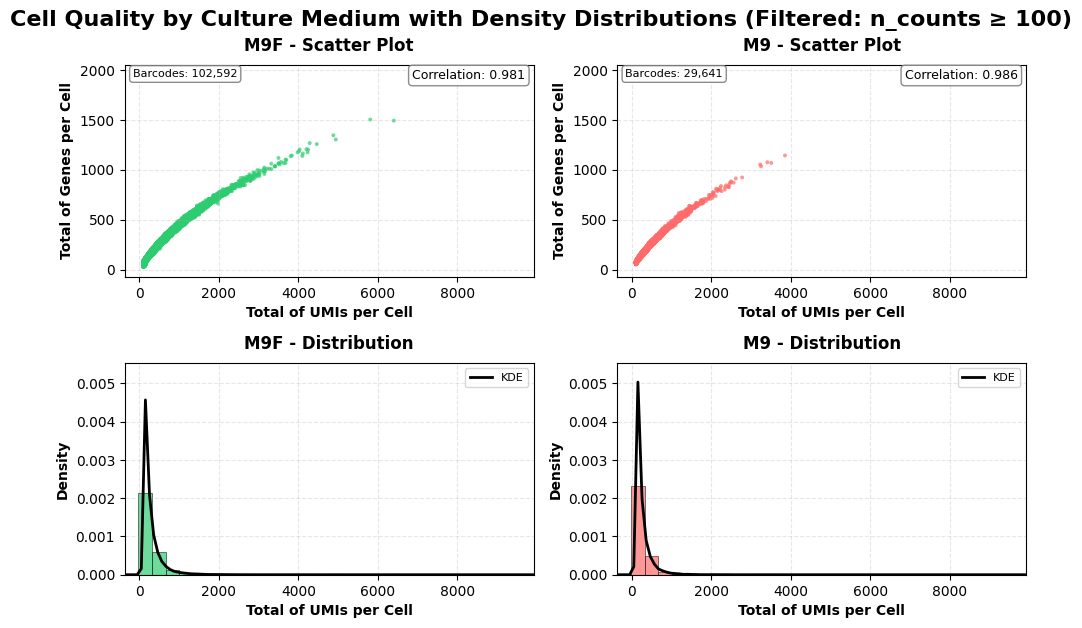


📊 Detailed Statistics by Culture Medium (After filtering: n_counts ≥ 100):

🍽️ M9F:
   📊 Total cells: 102,592
   📈 n_counts - Mean: 285, Median: 202
   📈 n_counts - Min: 100, Max: 9449
   🧬 n_genes - Mean: 155, Median: 123
   🧬 n_genes - Min: 27, Max: 1956
   🔗 Correlation n_counts vs n_genes: 0.981

🍽️ M9:
   📊 Total cells: 29,641
   📈 n_counts - Mean: 248, Median: 182
   📈 n_counts - Min: 100, Max: 3852
   🧬 n_genes - Mean: 146, Median: 118
   🧬 n_genes - Min: 53, Max: 1144
   🔗 Correlation n_counts vs n_genes: 0.986

3️⃣ Creating violin plot comparison...


/Users/valentingoupille/Internship_Val_Goupille_2025/code/Local_analysis/visualization_functions.py:697: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/Users/valentingoupille/Internship_Val_Goupille_2025/code/Local_analysis/visualization_functions.py:743: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


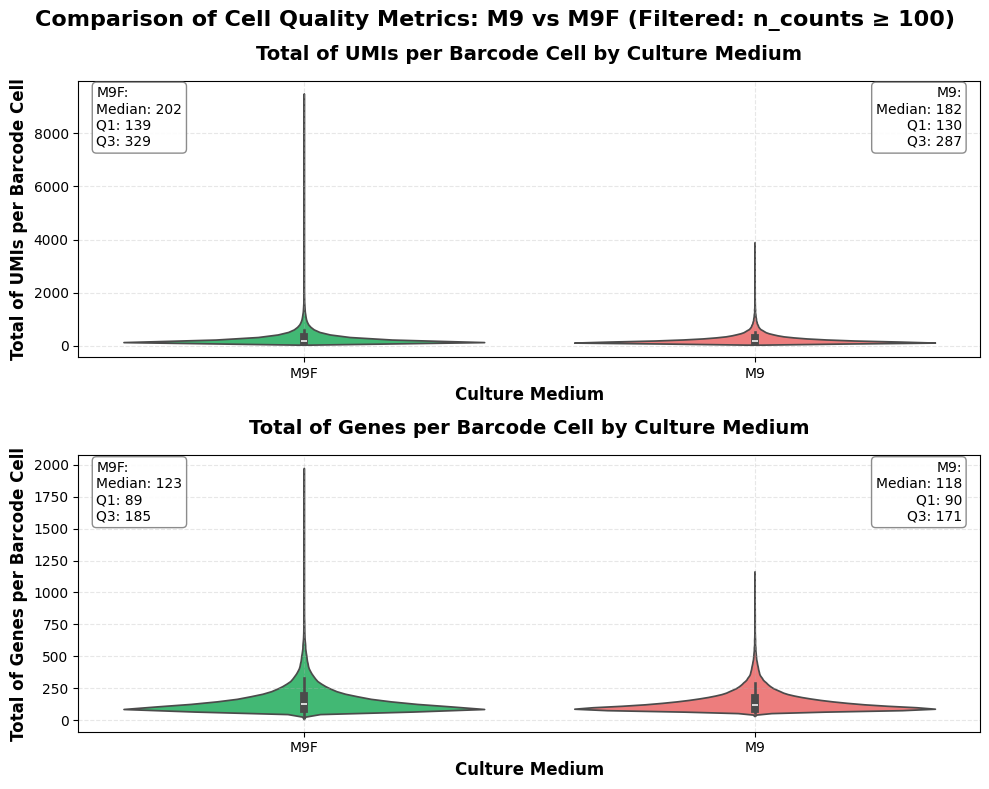


🎻 Violin Plot Comparison: M9 vs M9F
📊 Total cells in comparison: 132,233

🍽️ M9F:
   📊 Cells: 102,592
   📈 n_counts - Mean: 285, Median: 202
   📈 n_counts - Std: 257
   🧬 n_genes - Mean: 155, Median: 123
   🧬 n_genes - Std: 102

🍽️ M9:
   📊 Cells: 29,641
   📈 n_counts - Mean: 248, Median: 182
   📈 n_counts - Std: 203
   🧬 n_genes - Mean: 146, Median: 118
   🧬 n_genes - Std: 86

✅ All visualization functions completed successfully!


In [ ]:
# Run visualizations
run_visualizations(adata_filtered)

In [ ]:
# Save results
print("\n💾 Saving results...")
os.makedirs(OUTPUT_PATH, exist_ok=True)

# Save anndata object
output_file = os.path.join(OUTPUT_PATH, OUTPUT_FILE)
adata_filtered.write(output_file)

# Create CSV subdirectory for this step
csv_output_path = os.path.join(OUTPUT_PATH, "csv", "3a_filtering_100UMIs")
os.makedirs(csv_output_path, exist_ok=True)

# Save filtering statistics as CSV
# This CSV contains: initial_cells, cells_after_filtering, cells_removed, retention_rate_percent, threshold_applied, timestamp
stats_file = os.path.join(
    csv_output_path, OUTPUT_FILE.replace(".h5ad", "_filtering_stats.csv")
)
filtering_stats = pd.DataFrame(
    {
        "metric": [
            "initial_cells",
            "cells_after_filtering",
            "cells_removed",
            "retention_rate_percent",
            "threshold_applied",
            "timestamp",
        ],
        "value": [
            adata.n_obs,
            adata_filtered.n_obs,
            adata.n_obs - adata_filtered.n_obs,
            (adata_filtered.n_obs / adata.n_obs) * 100,
            UMI_THRESHOLD,
            datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        ],
    }
)
filtering_stats.to_csv(stats_file, index=False)

print(f"📁 Created directory: {OUTPUT_PATH}")
print(f"💾 Saved filtered anndata object to: {output_file}")
print(f"💾 Saved filtering statistics CSV to: {stats_file}")
print(
    f"📊 Saved {adata_filtered.n_obs:,} cells and {adata_filtered.n_vars:,} genes (filtered at {UMI_THRESHOLD} UMI)"
)


💾 Saving results...
📁 Created directory: data/Anndata/filtered
💾 Saved filtered anndata object to: data/Anndata/filtered/GeneFull_raw_unique_mult_with_metadata_grouped_filtered_100UMI.h5ad
💾 Saved filtering statistics CSV to: data/Anndata/filtered/csv/3a_filtering_100UMIs/GeneFull_raw_unique_mult_with_metadata_grouped_filtered_100UMI_filtering_stats.csv
📊 Saved 132,233 cells and 6,248 genes (filtered at 100 UMI)


In [ ]:
# Final summary
print("\n🎉 Analysis completed successfully!")
print("\n" + "=" * 60)
print("📊 FINAL SUMMARY")
print("=" * 60)
print(
    f"📊 Final dataset: {adata_filtered.n_obs:,} cells × {adata_filtered.n_vars:,} genes"
)
print(f"🔢 Initial cells:          {adata.n_obs:,}")
print(f"🔢 Cells after filtering:  {adata_filtered.n_obs:,}")
print(f"🗑️ Cells removed:          {adata.n_obs - adata_filtered.n_obs:,}")
print(f"✅ Retention rate:         {(adata_filtered.n_obs / adata.n_obs) * 100:.1f}%")
print(f"🎯 Threshold applied:      n_counts >= {UMI_THRESHOLD}")
print("=" * 60)
print(f"💾 AnnData object saved to: {output_file}")
print(f"💾 Filtering statistics CSV saved to: {stats_file}")


🎉 Analysis completed successfully!

📊 FINAL SUMMARY
📊 Final dataset: 132,233 cells × 6,248 genes
🔢 Initial cells:          820,800
🔢 Cells after filtering:  132,233
🗑️ Cells removed:          688,567
✅ Retention rate:         16.1%
🎯 Threshold applied:      n_counts >= 100
💾 AnnData object saved to: data/Anndata/filtered/GeneFull_raw_unique_mult_with_metadata_grouped_filtered_100UMI.h5ad
💾 Filtering statistics CSV saved to: data/Anndata/filtered/csv/3a_filtering_100UMIs/GeneFull_raw_unique_mult_with_metadata_grouped_filtered_100UMI_filtering_stats.csv
